In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('Student_Performance.csv')
df.sample(5)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
4598,9,65,No,8,7,64.0
8524,5,51,Yes,6,4,36.0
3519,3,48,Yes,7,0,28.0
5973,7,57,No,8,9,48.0
3682,5,83,No,4,6,69.0


In [ ]:
df.shape


(10000, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [ ]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [ ]:
display(df.isnull().sum())
print("duplicated rows: ",df.duplicated().sum())

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


duplicated rows:  0


In [ ]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

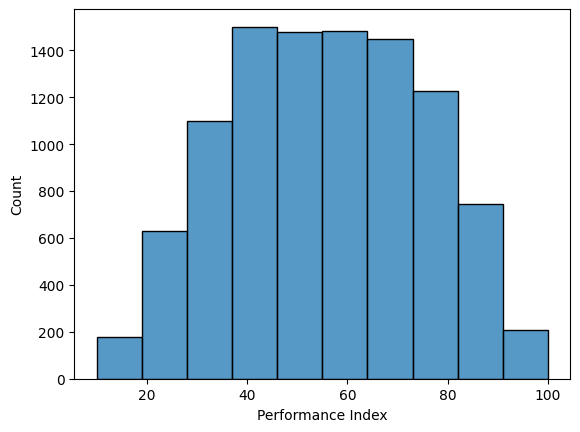

In [ ]:
sns.histplot(df['Performance Index'], bins=10)
plt.show()

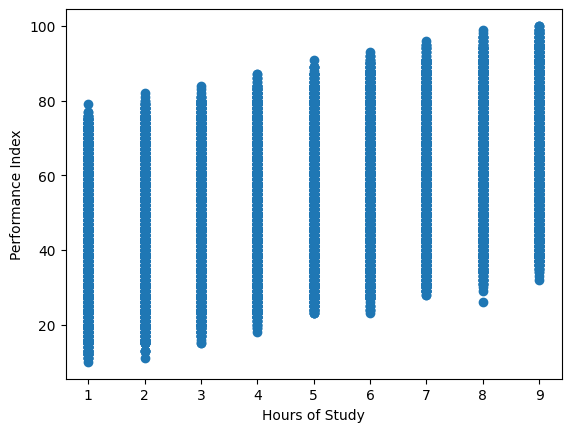

In [ ]:
plt.scatter(df['Hours Studied'], df['Performance Index'])
plt.xlabel('Hours of Study')
plt.ylabel('Performance Index')
plt.show()

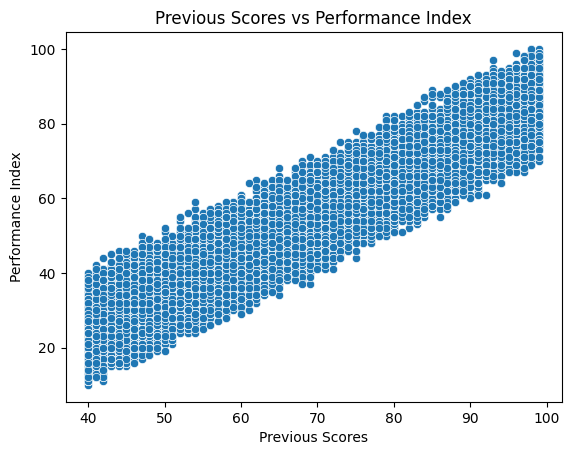

In [ ]:
sns.scatterplot(data=df, x='Previous Scores', y='Performance Index')

plt.xlabel('Previous Scores')
plt.ylabel('Performance Index')
plt.title('Previous Scores vs Performance Index')
plt.show()

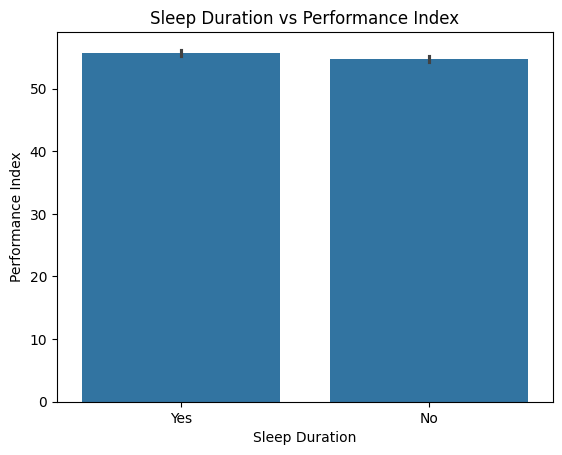

In [ ]:
sns.barplot(data=df, x='Extracurricular Activities', y='Performance Index')

plt.xlabel('Sleep Duration')
plt.ylabel('Performance Index')
plt.title('Sleep Duration vs Performance Index')
plt.show()

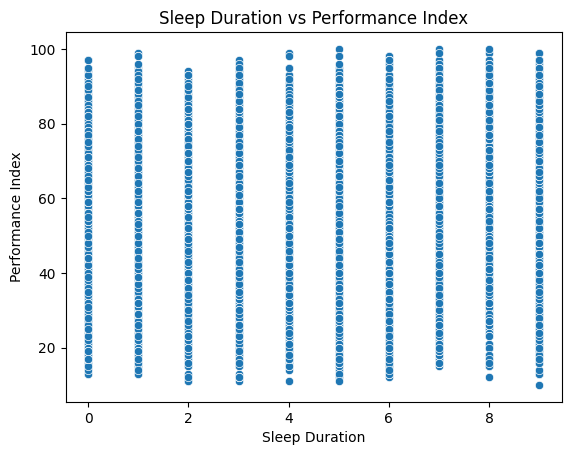

In [ ]:
sns.scatterplot(data=df, x='Sample Question Papers Practiced', y='Performance Index')

plt.xlabel('Sleep Duration')
plt.ylabel('Performance Index')
plt.title('Sleep Duration vs Performance Index')
plt.show()

In [ ]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({
    'Yes': 1,
    'No': 0
})

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
a = df[['Hours Studied',
        'Previous Scores',
        'Sleep Hours',
        'Sample Question Papers Practiced',
        'Extracurricular Activities']]

b = df['Performance Index']
a_train, a_test, b_train, b_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
a_train.shape

(8000, 4)

In [ ]:
lr1 = LinearRegression()
lr1.fit(a_train, b_train)

LinearRegression()

In [ ]:
b_pred =lr1.predict(a_test)

In [ ]:
print('R2 Score:', r2_score(b_test, b_pred))
mse = mean_squared_error(b_test, b_pred)
print('mean squared error:', mse)

R2 Score: 0.9887144552384186
mean squared error: 4.182254914593815
